In [1]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq
import matplotlib.cm as cm
import pyroomacoustics as pra
import numpy as np
import soundfile as sf

import sys
sys.path.append("/Users/kevinbrennan/Desktop/Diploma/Project/Code/HATS_Code") 

from HATS_functions import gcc_phat, corr_to_itd

angles = ["-90", "-67.5", "-45", "-22.5", "0", "22.5", "45", "67.5", "90"]

height = 'H3'
source_angle = '-45'
PathToFiles = f"../Audio_Files/Mic_Array/Vertical/{height}"

num_mics = 7
fs = 48000

recordings = {}

for angle in angles:
    folder = Path(PathToFiles) / str(angle)
    if folder.is_dir():
        recordings[angle] = {
                '0': folder / "Untitled 1-Audio.wav",
                '1': folder / "Untitled 2-Audio.wav",
                '2': folder / "Untitled 3-Audio.wav",
                '3': folder / "Untitled 4-Audio.wav",
                '4': folder / "Untitled 5-Audio.wav",
                '5': folder / "Untitled 6-Audio.wav",
                '6': folder / "Untitled 7-Audio.wav",
                '7': folder / "Untitled 8-Audio.wav"
            }
    else:
        print(f"Missing folder: {folder}")
        
r = 0.045
mic_angles_deg = [0, 60, 120, 180, 240, 300]

positions = [[0, 0, 0]]
for a in mic_angles_deg:
    theta = np.radians(a)
    positions.append([0, -r * np.sin(theta), r * np.cos(theta)])

mic_positions = np.array(positions).T

In [2]:
signals = []
for i in range(7):
    data, fs = sf.read(recordings[source_angle][str(i)])
    if data.ndim > 1:
        data = data.mean(axis=1)
    signals.append(data)

min_len = min(len(s) for s in signals)
signals = np.stack([s[:min_len] for s in signals])

# STFT
nfft = 256
hop = nfft // 2
X = pra.transform.stft.analysis(signals.T, L=nfft, hop=hop)
X = X.transpose(2, 1, 0)

# SRP-PHAT
azimuth_grid = np.linspace(-np.pi/2, np.pi/2, 181)  
colatitude_grid = np.linspace(0, np.pi, 181) 

doa = pra.doa.algorithms['MUSIC'](mic_positions, fs, nfft, c=343, num_src=1, dim=3, azimuth=azimuth_grid, colatitude=colatitude_grid)
doa.locate_sources(X)

azimuth_deg = np.degrees(doa.azimuth_recon[0])
elevation_deg = 90 - np.degrees(doa.colatitude_recon[0])

print(f"Source angle:    {source_angle}°")
print(f"Height:    {height}")
print(f"Azimuth:   {azimuth_deg:+.1f}°")
print(f"Elevation: {elevation_deg:+.1f}°")

Source angle:    -45°
Height:    H3
Azimuth:   -20.0°
Elevation: -2.0°



--- H3 ---
  true az=   -90° → az= -55.0° (+35.0°)  el= +11.0° ( -3.0°)
  true az= -67.5° → az= -33.0° (+34.5°)  el=  +5.0° ( -9.0°)
  true az=   -45° → az= -27.0° (+18.0°)  el=  +8.0° ( -6.0°)
  true az= -22.5° → az= -11.0° (+11.5°)  el=  +4.0° (-10.0°)
  true az=     0° → az=  +1.0° ( +1.0°)  el=  +5.0° ( -9.0°)
  true az=  22.5° → az= +19.0° ( -3.5°)  el=  +5.0° ( -9.0°)
  true az=    45° → az= +30.0° (-15.0°)  el=  +3.0° (-11.0°)
  true az=  67.5° → az= +43.0° (-24.5°)  el=  +1.0° (-13.0°)
  true az=    90° → az= +44.0° (-46.0°)  el=  -2.0° (-16.0°)


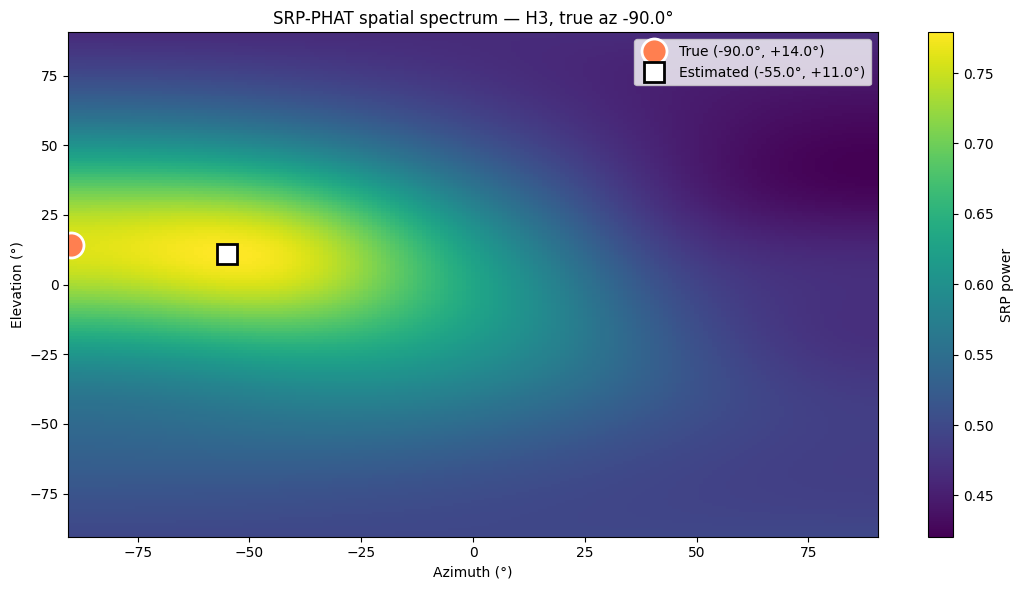

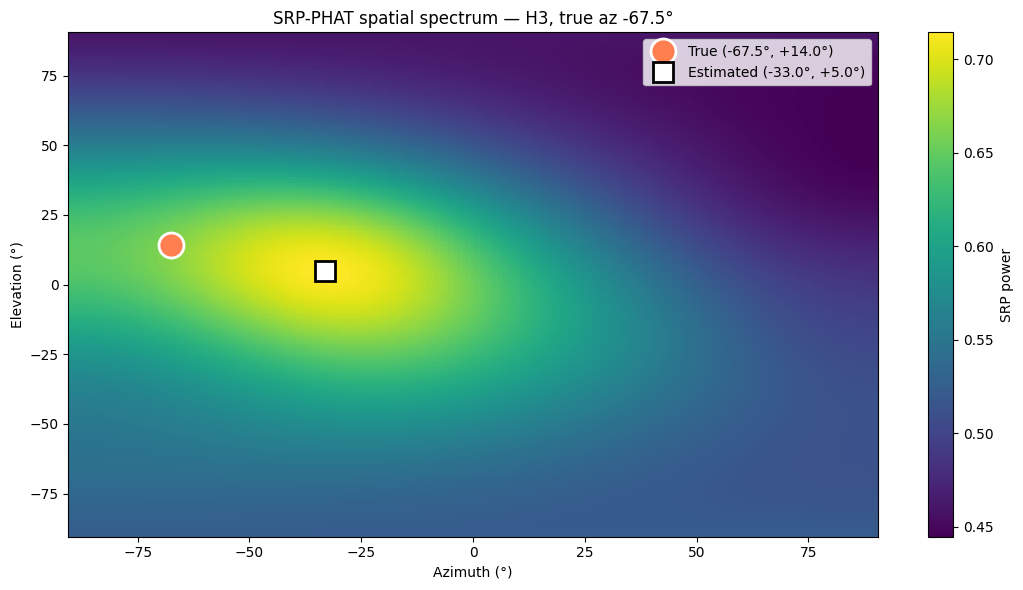

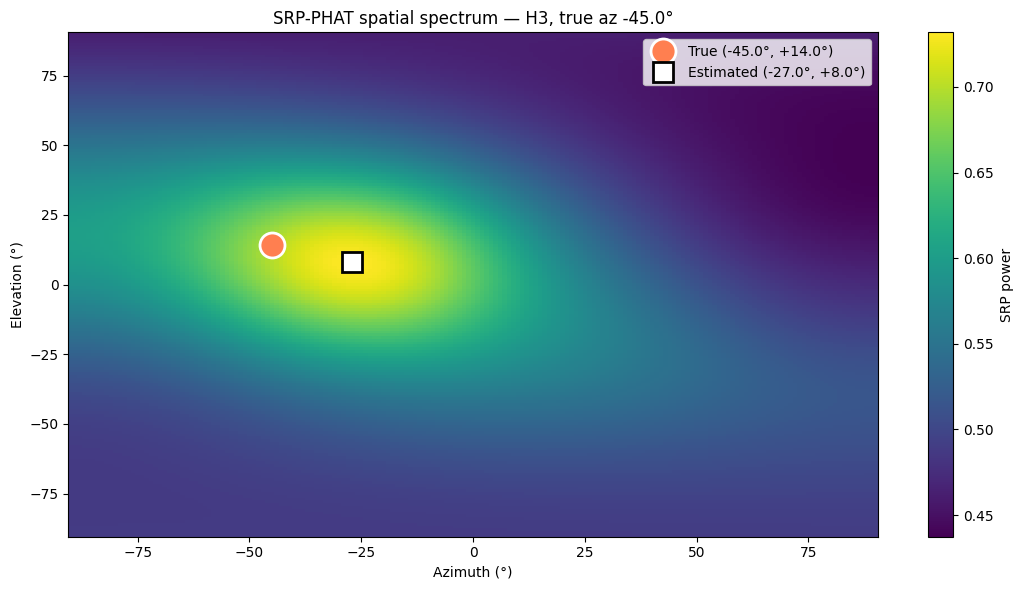

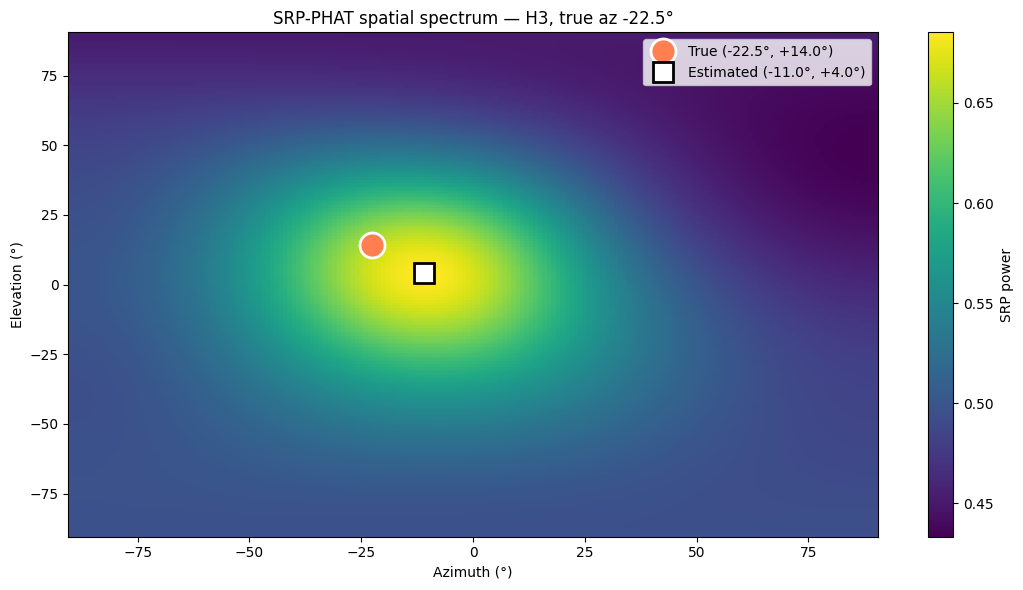

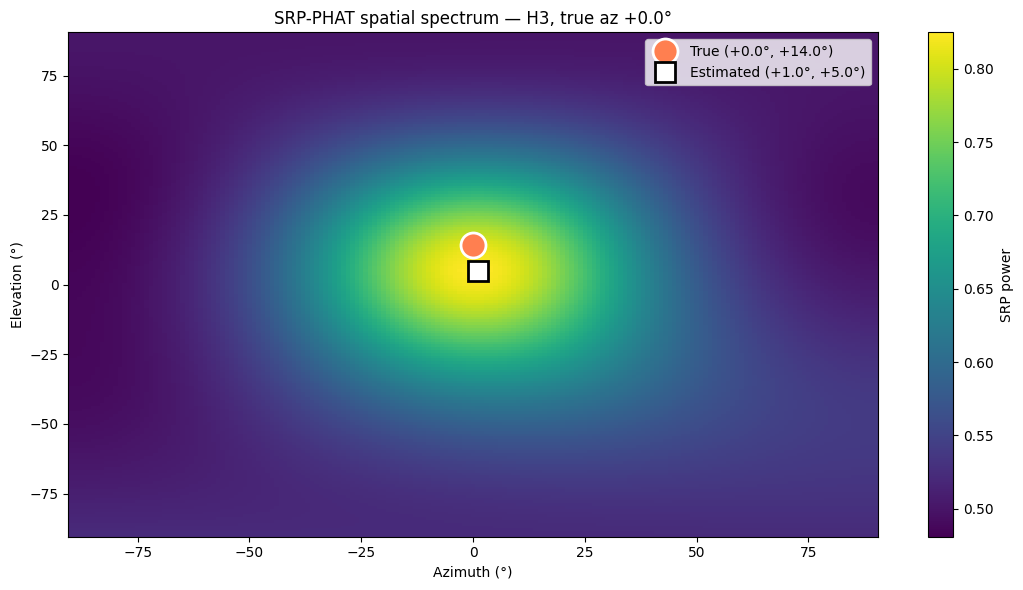

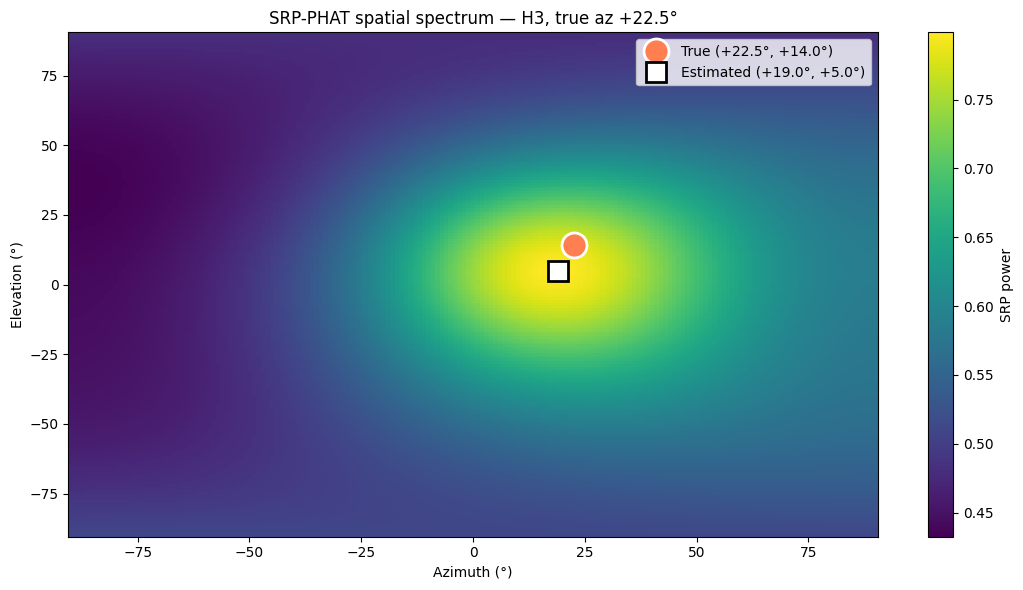

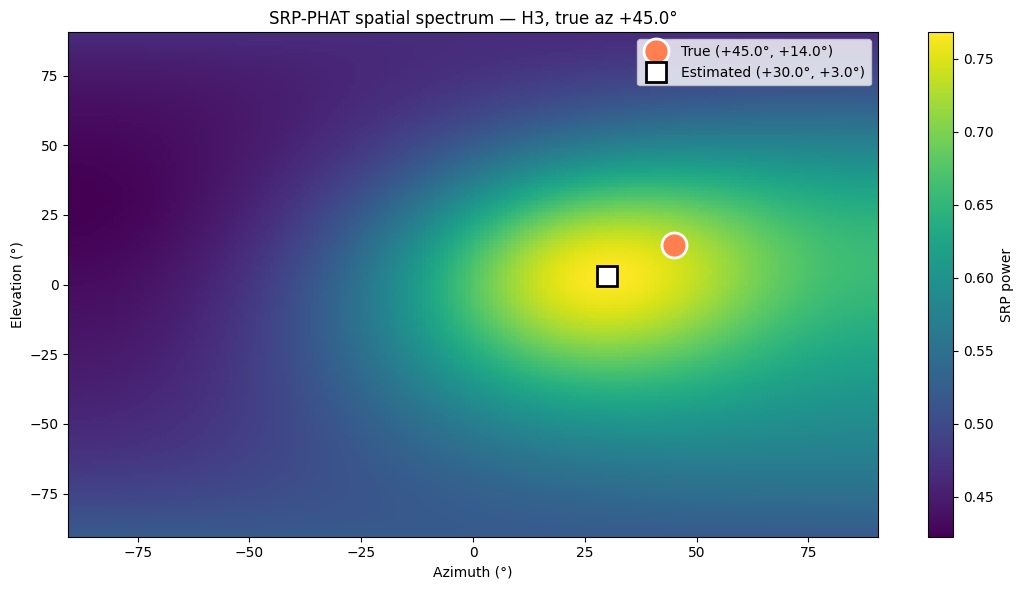

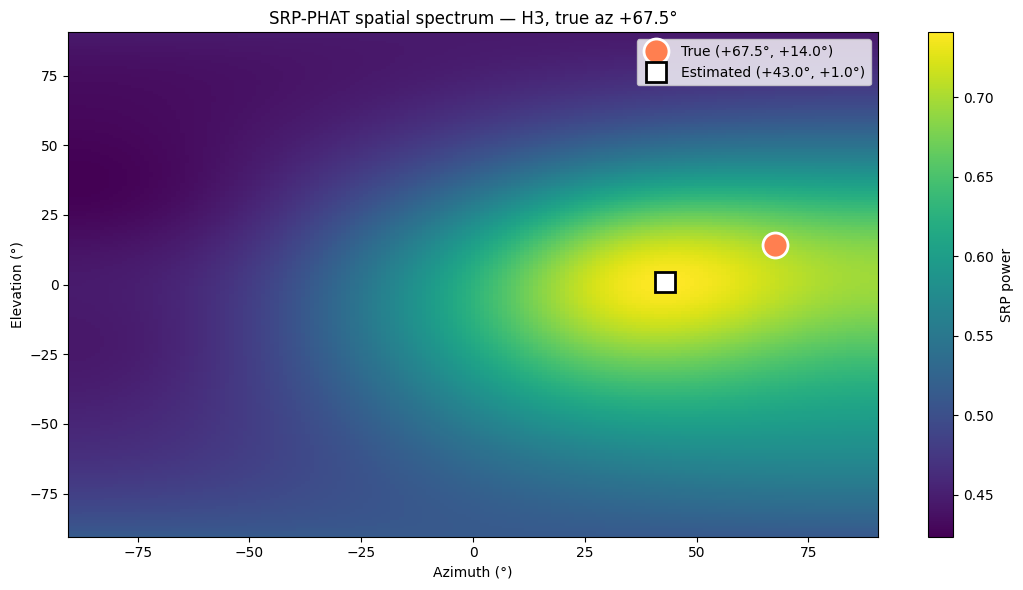

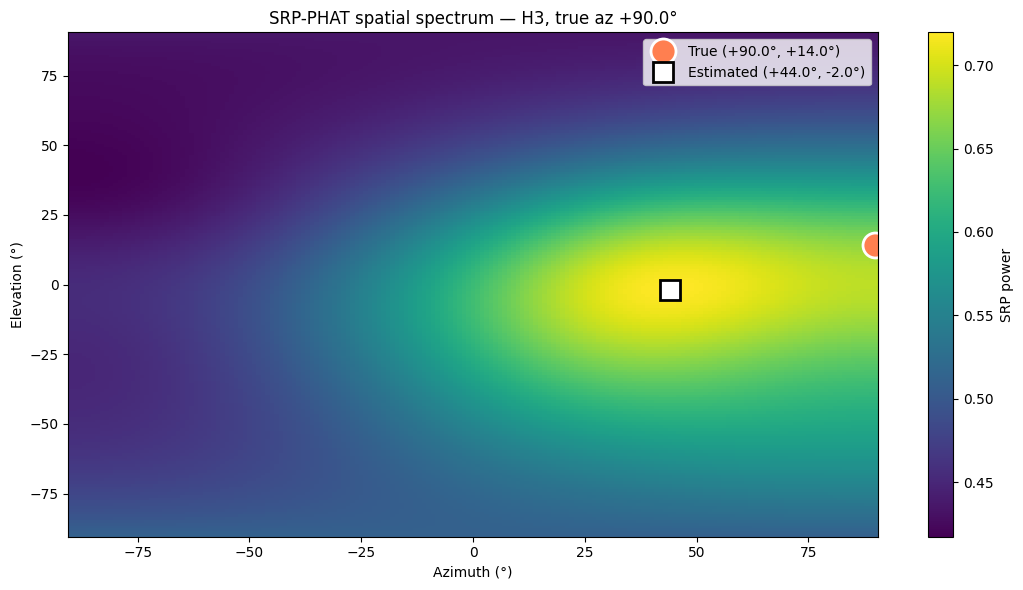

In [3]:
def run_music_3d(recording_dict):
    signals = []
    for i in range(7):
        data, fs = sf.read(recording_dict[str(i)])
        if data.ndim > 1:
            data = data.mean(axis=1)
        signals.append(data)

    min_len = min(len(s) for s in signals)
    signals = np.stack([s[:min_len] for s in signals])

    nfft = 256
    hop = nfft // 2
    X = pra.transform.stft.analysis(signals.T, L=nfft, hop=hop)
    X = X.transpose(2, 1, 0)

    azimuth_grid = np.linspace(-np.pi/2, np.pi/2, 181)
    colatitude_grid = np.linspace(0, np.pi, 181)

    doa = pra.doa.algorithms['SRP'](
        mic_positions, fs, nfft, c=343, num_src=1, dim=3,
        azimuth=azimuth_grid,
        colatitude=colatitude_grid
    )
    doa.locate_sources(X)
    return doa


srp_results = {}

d = 1.6
heights_m = {'H1': 1.30, 'H2': 1.70, 'H3': 2.10}
array_height = 1.7
print(f"\n--- {height} ---")
h_diff = heights_m[height] - array_height
expected_el = np.degrees(np.arctan2(h_diff, d))

srp_results[height] = {}
for angle_key in sorted(recordings.keys(), key=float):
    doa = run_music_3d(recordings[angle_key])
    srp_results[height][angle_key] = doa
    az = np.degrees(doa.azimuth_recon[0])
    el = 90 - np.degrees(doa.colatitude_recon[0])
    az_err = az - float(angle_key)
    el_err = el - expected_el
    print(f"  true az={angle_key:>6}° → az={az:+6.1f}° ({az_err:+5.1f}°)  el={el:+6.1f}° ({el_err:+5.1f}°)")
    
import matplotlib.cm as cm
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


def save_fig(fig, name):
    fig.savefig(figures_dir / f"{name}.png", dpi=200, bbox_inches='tight')
    fig.savefig(figures_dir / f"{name}.pdf", bbox_inches='tight')


def plot_srp_spectrum_heatmap(doa, true_az, true_el, height_label, name):
    az_grid = doa.grid.azimuth
    col_grid = doa.grid.colatitude

    n_az = len(np.unique(az_grid))
    n_col = len(np.unique(col_grid))
    spectrum = doa.grid.values.reshape(n_col, n_az)

    az_deg = np.degrees(np.unique(az_grid))
    el_deg = 90 - np.degrees(np.unique(col_grid))

    fig, ax = plt.subplots(figsize=(11, 6))
    im = ax.pcolormesh(az_deg, el_deg, spectrum,
                        cmap='viridis', shading='auto')

    est_az = np.degrees(doa.azimuth_recon[0])
    est_el = 90 - np.degrees(doa.colatitude_recon[0])
    ax.plot(true_az, true_el, 'o', color='coral', markersize=18,
            markeredgecolor='white', markeredgewidth=2,
            label=f'True ({true_az:+.1f}°, {true_el:+.1f}°)')
    ax.plot(est_az, est_el, 's', color='white', markersize=14,
            markeredgecolor='black', markeredgewidth=2,
            label=f'Estimated ({est_az:+.1f}°, {est_el:+.1f}°)')

    ax.set_xlabel('Azimuth (°)')
    ax.set_ylabel('Elevation (°)')
    ax.set_title(f'SRP-PHAT spatial spectrum — {height_label}, true az {true_az:+.1f}°')
    ax.legend(loc='upper right')

    plt.colorbar(im, ax=ax, label='SRP power')
    plt.tight_layout()
    save_fig(fig, name)
    plt.show()
    plt.close(fig)


for angle_key in sorted(recordings.keys(), key=float):
    doa = srp_results[height][angle_key]
    h_diff = heights_m[height] - array_height
    true_el = np.degrees(np.arctan2(h_diff, d))
    plot_srp_spectrum_heatmap(
        doa=doa,
        true_az=float(angle_key),
        true_el=true_el,
        height_label=height,
        name=f"srp_spectrum_{height}_{angle_key}"
    )

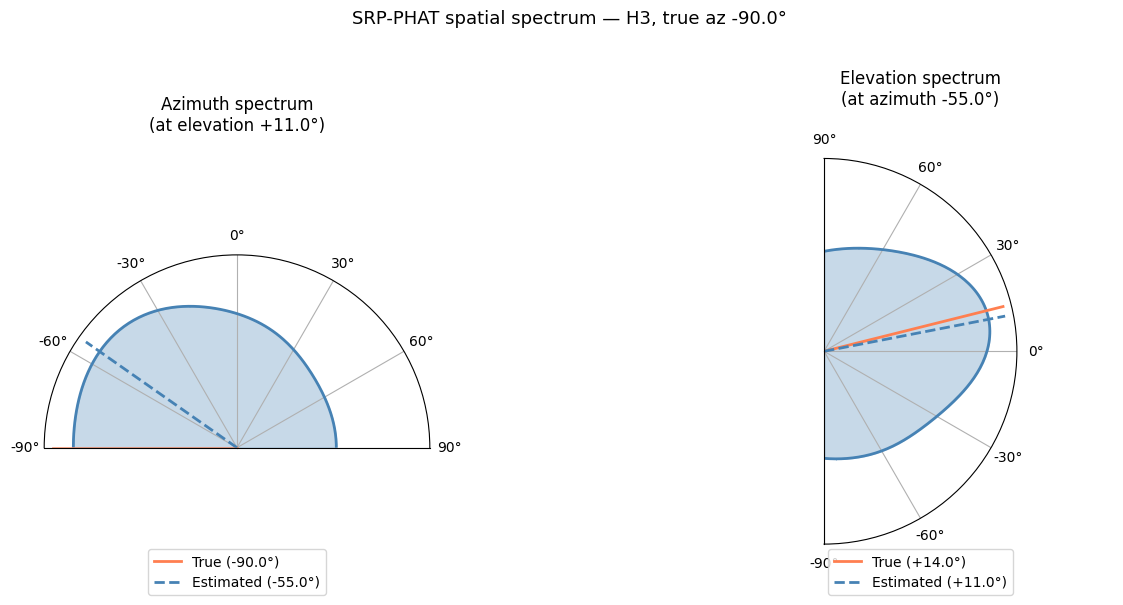

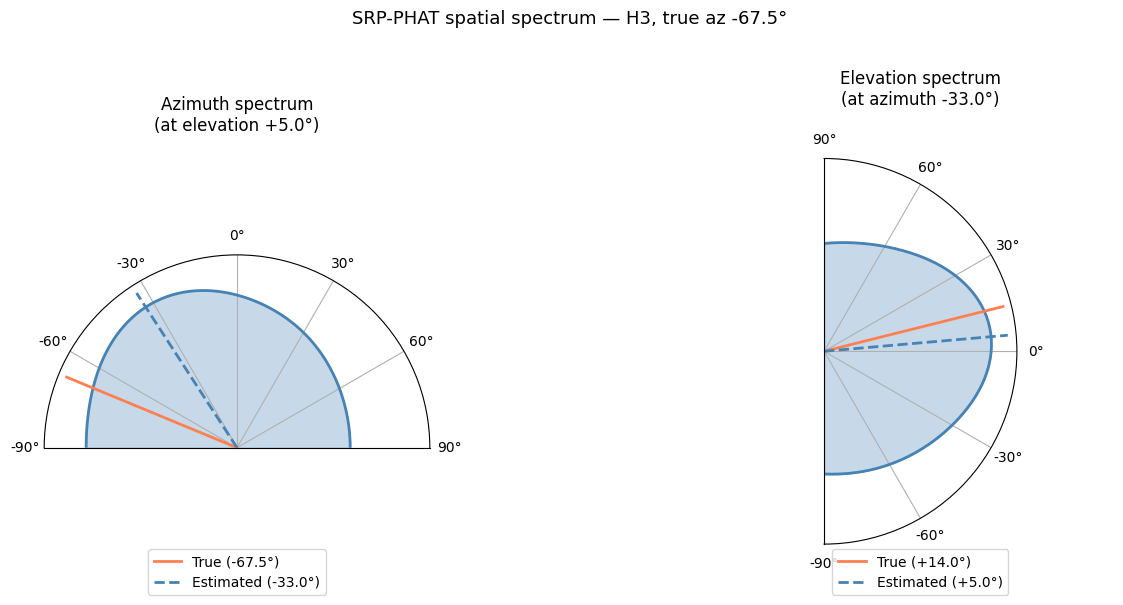

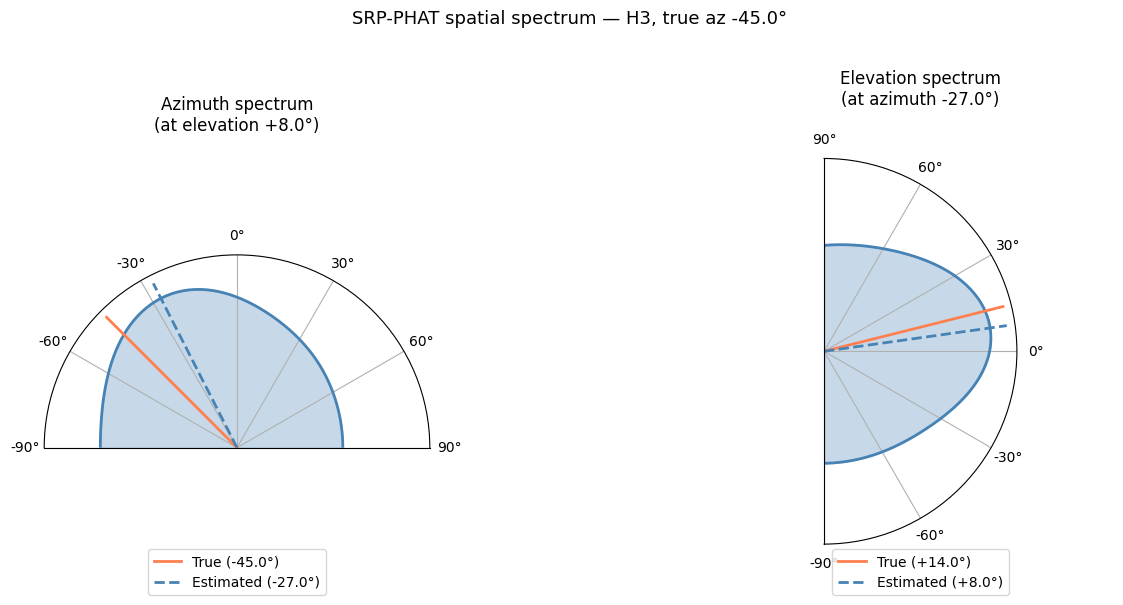

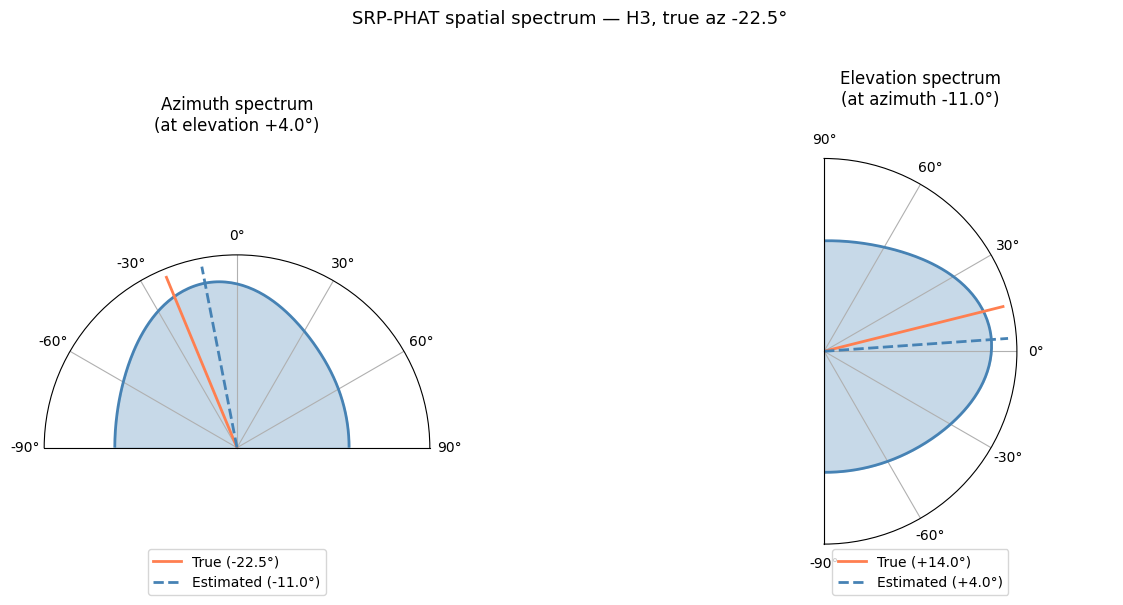

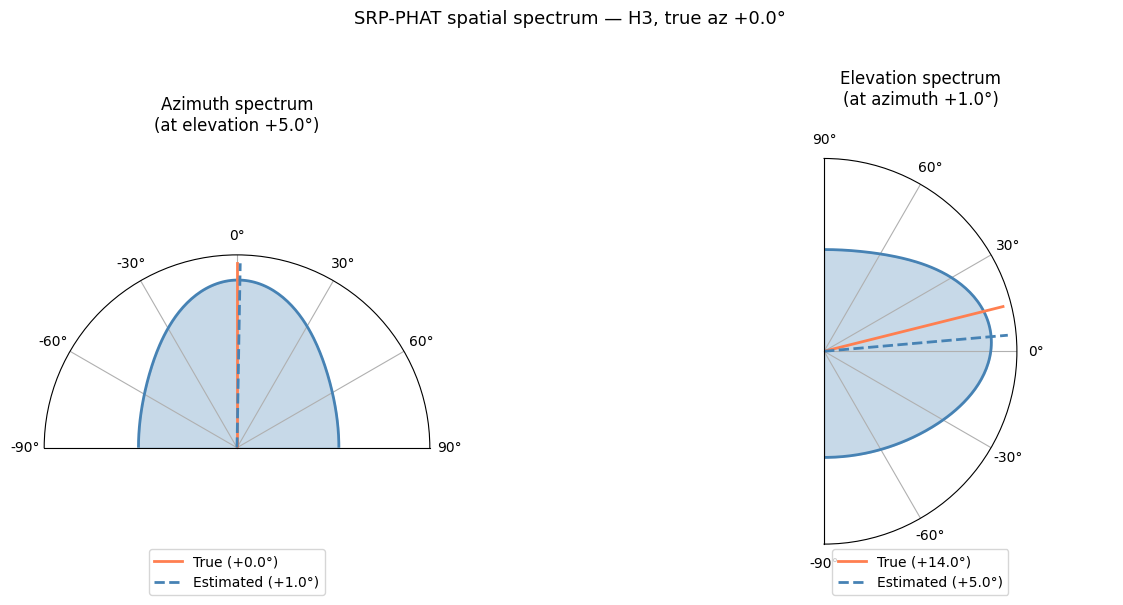

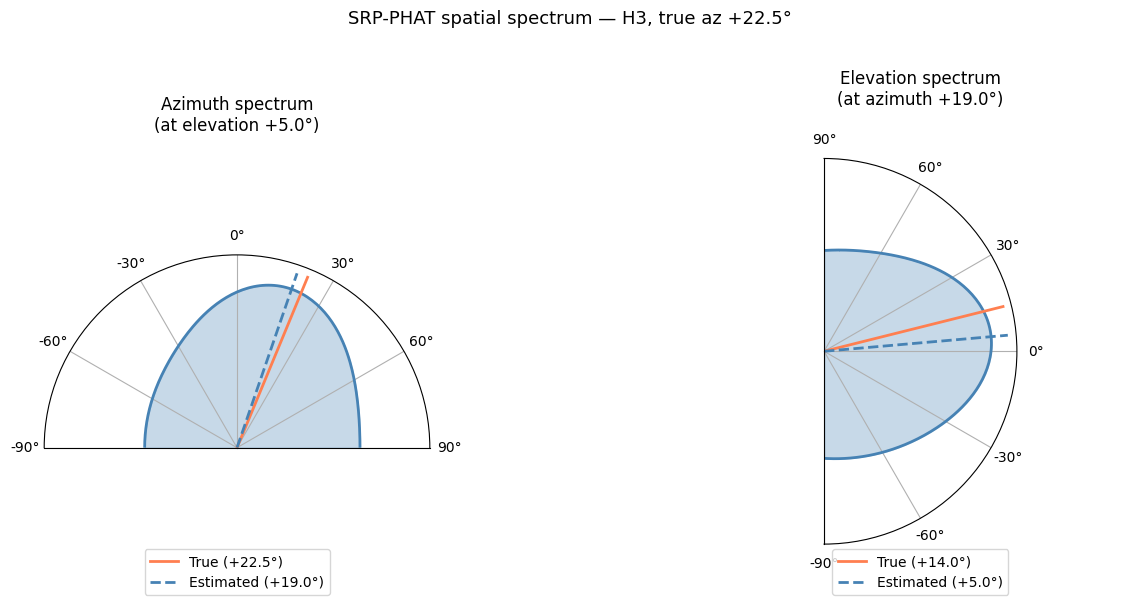

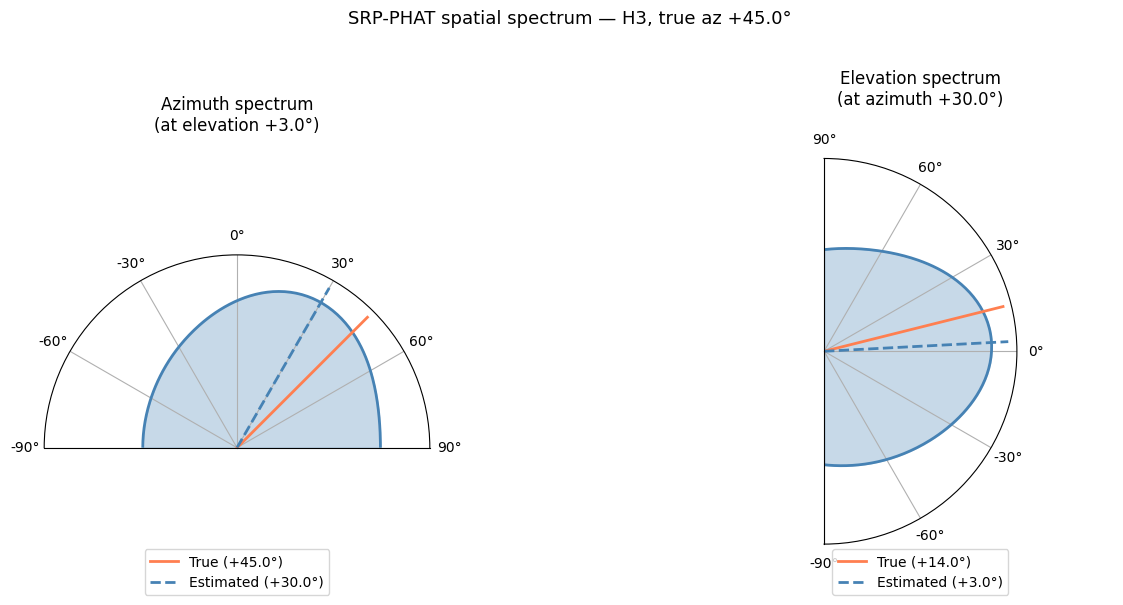

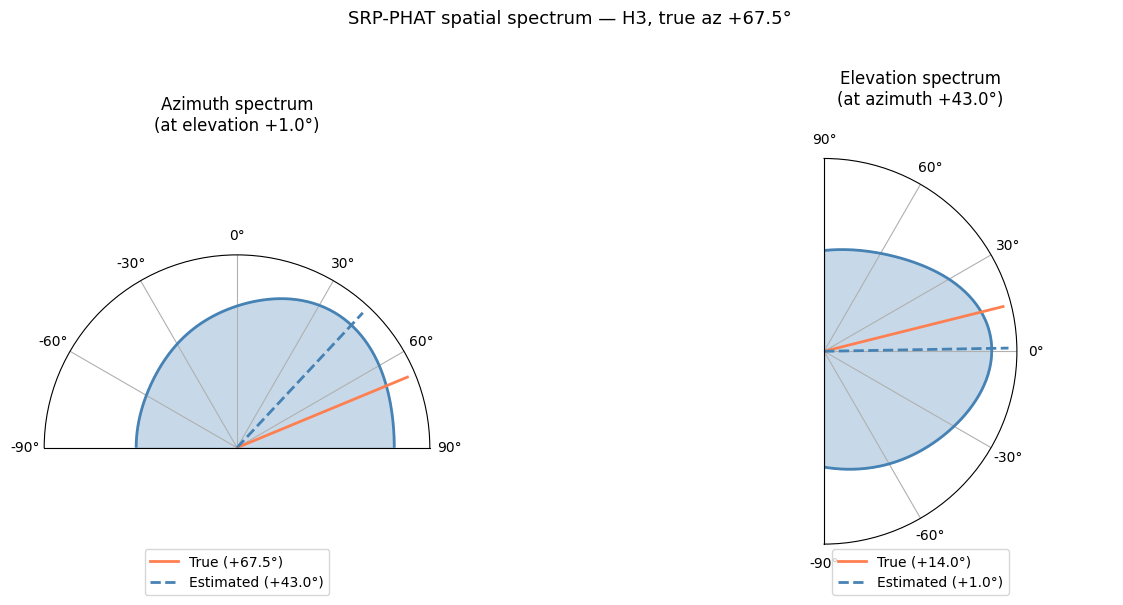

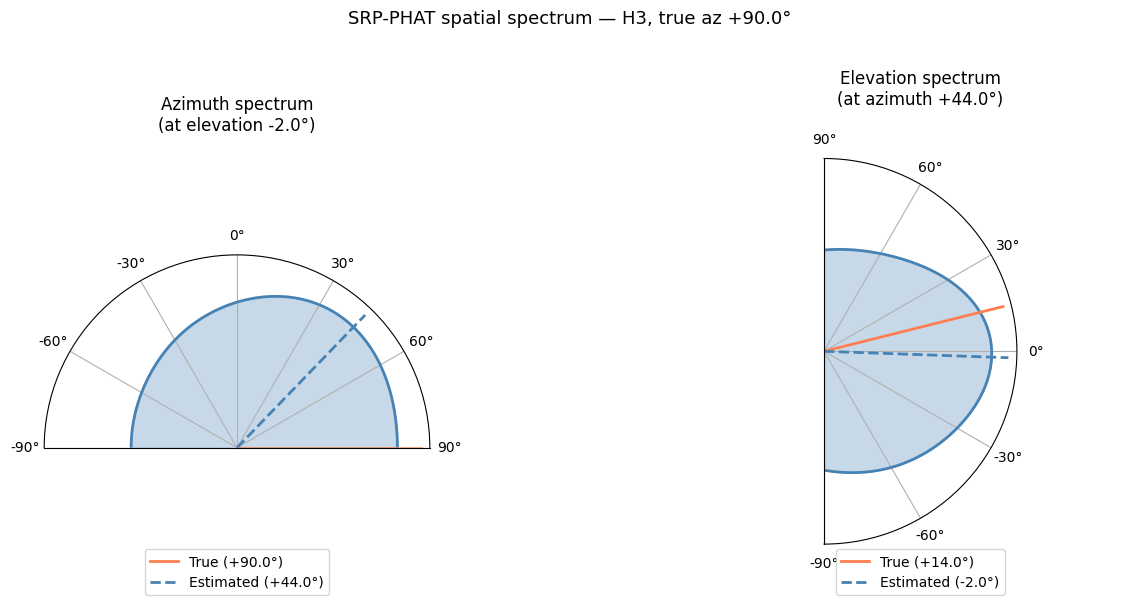

In [4]:
def plot_srp_slices(doa, true_az, true_el, height_label, name):
    az_grid = np.unique(doa.grid.azimuth)
    col_grid = np.unique(doa.grid.colatitude)
    n_az = len(az_grid)
    n_col = len(col_grid)
    spectrum = doa.grid.values.reshape(n_col, n_az)

    est_az = doa.azimuth_recon[0]
    est_col = doa.colatitude_recon[0]
    est_az_deg = np.degrees(est_az)
    est_el_deg = 90 - np.degrees(est_col)

    col_idx = np.argmin(np.abs(col_grid - est_col))
    az_slice = spectrum[col_idx, :]
    az_slice_norm = az_slice / az_slice.max()


    az_idx = np.argmin(np.abs(az_grid - est_az))
    col_slice = spectrum[:, az_idx]
    col_slice_norm = col_slice / col_slice.max()
    el_grid = 90 - np.degrees(col_grid)  

    fig, (ax_az, ax_el) = plt.subplots(
        1, 2, figsize=(14, 6),
        subplot_kw={'projection': 'polar'}
    )


    ax_az.set_theta_zero_location('N')
    ax_az.set_theta_direction(-1)
    ax_az.set_thetamin(-90)
    ax_az.set_thetamax(90)

    ax_az.plot(az_grid, az_slice_norm, color='steelblue', linewidth=2)
    ax_az.fill_between(az_grid, 0, az_slice_norm, alpha=0.3, color='steelblue')

    ax_az.plot([np.radians(true_az)] * 2, [0, 1.1],
            color='coral', lw=2, label=f'True ({true_az:+.1f}°)')
    ax_az.plot([est_az] * 2, [0, 1.1],
            color='steelblue', lw=2, linestyle='--',
            label=f'Estimated ({est_az_deg:+.1f}°)')

    ax_az.set_ylim(0, 1.15)
    ax_az.set_rticks([])
    ax_az.set_thetagrids(np.arange(-90, 91, 30),
                        labels=[f'{a}°' for a in np.arange(-90, 91, 30)])
    ax_az.set_title(f'Azimuth spectrum\n(at elevation {est_el_deg:+.1f}°)', pad=20)
    ax_az.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15))


    ax_el.set_theta_zero_location('E')
    ax_el.set_theta_direction(1)
    ax_el.plot(np.radians(el_grid), col_slice_norm,
               color='steelblue', linewidth=2)
    ax_el.fill_between(np.radians(el_grid), 0, col_slice_norm,
                       alpha=0.3, color='steelblue')

    ax_el.plot([np.radians(true_el)] * 2, [0, 1.1],
               color='coral', lw=2, label=f'True ({true_el:+.1f}°)')
    ax_el.plot([np.radians(est_el_deg)] * 2, [0, 1.1],
               color='steelblue', lw=2, linestyle='--',
               label=f'Estimated ({est_el_deg:+.1f}°)')

    ax_el.set_ylim(0, 1.15)
    ax_el.set_rticks([])
    ax_el.set_thetamin(-90)
    ax_el.set_thetamax(90)
    ax_el.set_title(f'Elevation spectrum\n(at azimuth {est_az_deg:+.1f}°)', pad=20)
    ax_el.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15))

    fig.suptitle(f'SRP-PHAT spatial spectrum — {height_label}, true az {true_az:+.1f}°',
                 fontsize=13, y=1.02)
    plt.tight_layout()

    save_fig(fig, name)
    plt.show()
    plt.close(fig)


for angle_key in sorted(srp_results[height].keys(), key=float):
    doa = srp_results[height][angle_key]
    h_diff = heights_m[height] - array_height
    true_el = np.degrees(np.arctan2(h_diff, d))
    plot_srp_slices(
        doa=doa,
        true_az=float(angle_key),
        true_el=true_el,
        height_label=height,
        name=f"srp_slices_{height}_{angle_key}"
    )

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import soundfile as sf
import pyroomacoustics as pra
from pathlib import Path


figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


def save_fig(fig, name):
    fig.savefig(figures_dir / f"{name}.png", dpi=200, bbox_inches='tight')
    fig.savefig(figures_dir / f"{name}.pdf", bbox_inches='tight')


angles = ["-90", "-67.5", "-45", "-22.5", "0", "22.5", "45", "67.5", "90"]
angles_float = [float(a) for a in angles]
heights = ['H1', 'H2', 'H3']

d = 1.6
heights_m = {'H1': 1.30, 'H2': 1.70, 'H3': 2.10}
array_height = 1.70

# Array geometry
r = 0.045
mic_angles_deg = [0, 60, 120, 180, 240, 300]
positions = [[0, 0, 0]]
for a in mic_angles_deg:
    theta = np.radians(a)
    positions.append([0, -r * np.sin(theta), r * np.cos(theta)])
mic_positions = np.array(positions).T


recordings = {}
for h in heights:
    recordings[h] = {}
    PathToFiles = f"../Audio_Files/Mic_Array/Vertical/{h}"
    for angle in angles:
        folder = Path(PathToFiles) / str(angle)
        if folder.is_dir():
            recordings[h][angle] = {
                str(i): folder / f"Untitled {i+1}-Audio.wav"
                for i in range(7)
            }
        else:
            print(f"Missing folder: {folder}")


def run_doa(recording_dict, algorithm='SRP'):
    signals = []
    for i in range(7):
        data, fs = sf.read(recording_dict[str(i)])
        if data.ndim > 1:
            data = data.mean(axis=1)
        signals.append(data)

    min_len = min(len(s) for s in signals)
    signals = np.stack([s[:min_len] for s in signals])

    nfft = 256
    hop = nfft // 2
    X = pra.transform.stft.analysis(signals.T, L=nfft, hop=hop)
    X = X.transpose(2, 1, 0)

    azimuth_grid = np.linspace(-np.pi/2, np.pi/2, 181)
    colatitude_grid = np.linspace(0, np.pi, 181)

    doa = pra.doa.algorithms[algorithm](
        mic_positions, fs, nfft, c=343, num_src=1, dim=3,
        azimuth=azimuth_grid,
        colatitude=colatitude_grid
    )
    doa.locate_sources(X)
    return doa


music_results = {}
srp_results = {}
for h in heights:
    print(f"\n--- Running DOA for {h} ---")
    music_results[h] = {}
    srp_results[h] = {}
    for angle in angles:
        if angle not in recordings[h]:
            continue
        print(f"  {angle}°...")
        music_results[h][angle] = run_doa(recordings[h][angle], 'MUSIC')
        srp_results[h][angle]   = run_doa(recordings[h][angle], 'SRP')


global_vmax = 0
for h in heights:
    h_diff = heights_m[h] - array_height
    expected_el = np.degrees(np.arctan2(h_diff, d))
    for angle in angles:
        if angle not in music_results[h]:
            continue
        true_az = float(angle)
        for doa in [music_results[h][angle], srp_results[h][angle]]:
            est_az = np.degrees(doa.azimuth_recon[0])
            est_el = 90 - np.degrees(doa.colatitude_recon[0])
            global_vmax = max(global_vmax,
                              abs(est_az - true_az),
                              abs(est_el - expected_el))


--- Running DOA for H1 ---
  -90°...
  -67.5°...
  -45°...
  -22.5°...
  0°...
  22.5°...
  45°...
  67.5°...
  90°...

--- Running DOA for H2 ---
  -90°...
  -67.5°...
  -45°...
  -22.5°...
  0°...
  22.5°...
  45°...
  67.5°...
  90°...

--- Running DOA for H3 ---
  -90°...
  -67.5°...
  -45°...
  -22.5°...
  0°...
  22.5°...
  45°...
  67.5°...
  90°...


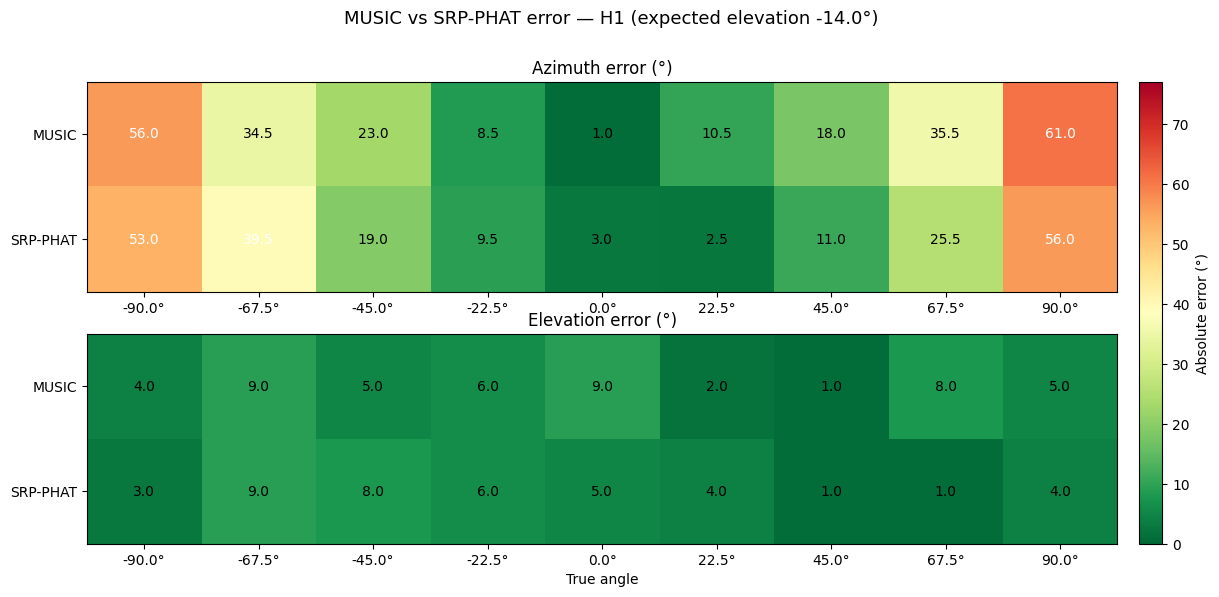

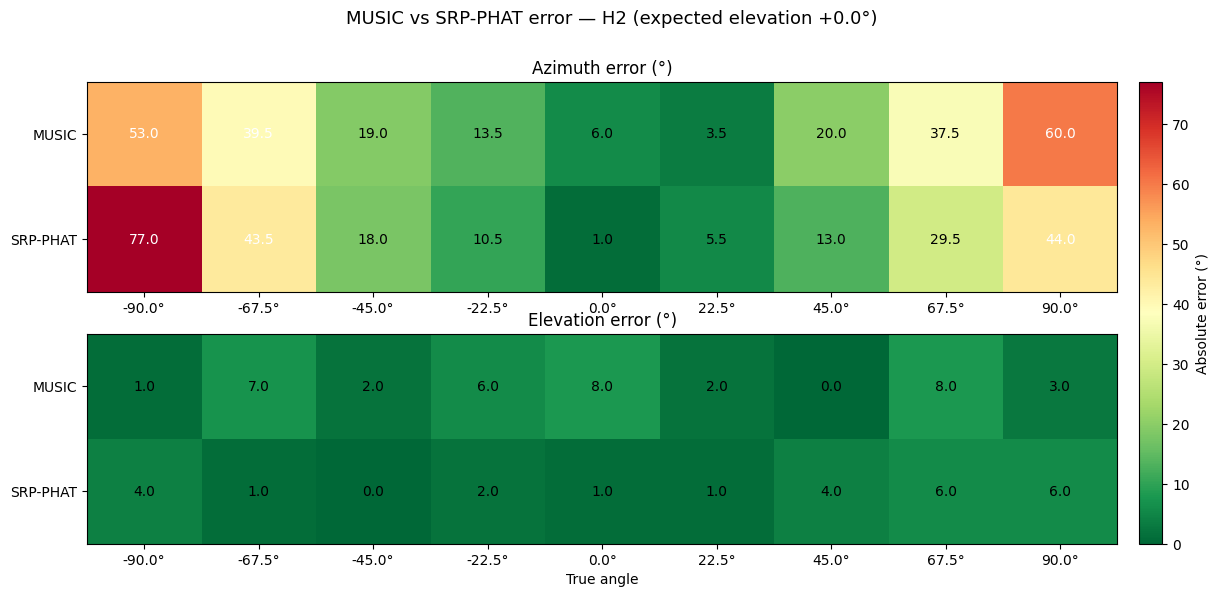

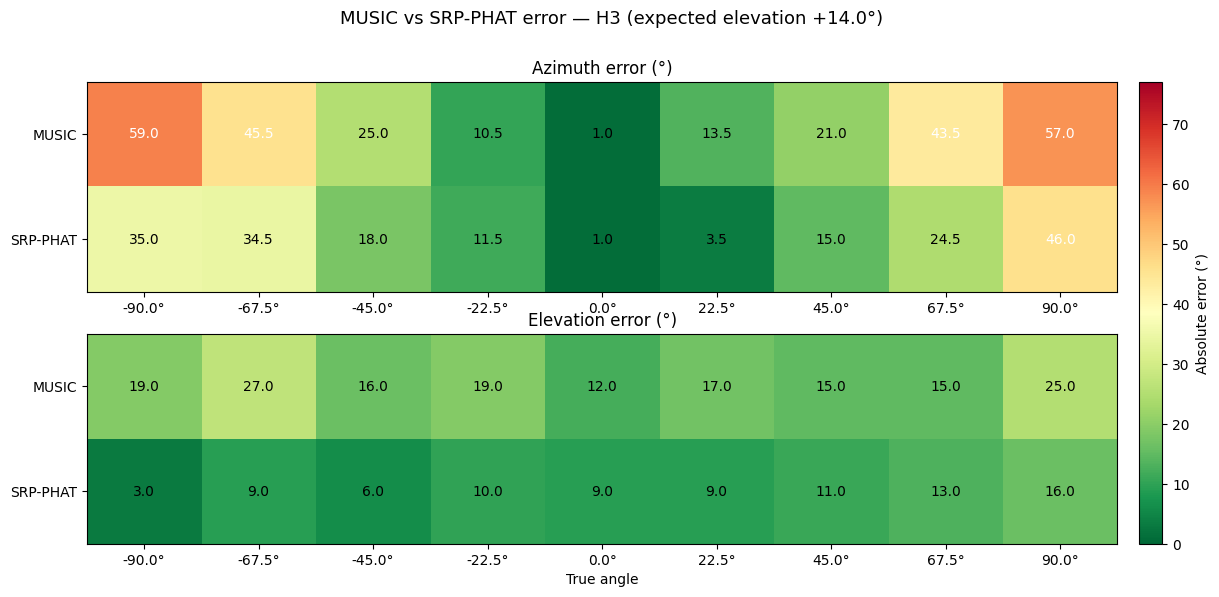

In [6]:

def plot_music_vs_srp_errors(music_h, srp_h, height_label, name, vmax):
    h_diff = heights_m[height_label] - array_height
    expected_el = np.degrees(np.arctan2(h_diff, d))

    n_angles = len(angles)
    grid = np.zeros((2, 2, n_angles)) 

    for j, angle in enumerate(angles):
        true_az = float(angle)
        for m_idx, results in enumerate([music_h, srp_h]):
            doa = results[angle]
            est_az = np.degrees(doa.azimuth_recon[0])
            est_el = 90 - np.degrees(doa.colatitude_recon[0])
            grid[m_idx, 0, j] = abs(est_az - true_az)
            grid[m_idx, 1, j] = abs(est_el - expected_el)

    fig, axes = plt.subplots(2, 1, figsize=(14, 6))
    metrics = ['Azimuth error (°)', 'Elevation error (°)']

    for metric_idx, ax in enumerate(axes):
        data = grid[:, metric_idx, :]
        im = ax.imshow(data, cmap='RdYlGn_r', aspect='auto',
                       vmin=0, vmax=vmax)

        ax.set_xticks(range(n_angles))
        ax.set_xticklabels([f'{a}°' for a in angles_float])
        ax.set_yticks([0, 1])
        ax.set_yticklabels(['MUSIC', 'SRP-PHAT'])
        ax.set_title(metrics[metric_idx])

        for i in range(2):
            for j in range(n_angles):
                val = data[i, j]
                ax.text(j, i, f'{val:.1f}', ha='center', va='center',
                        fontsize=10,
                        color='white' if val > vmax * 0.5 else 'black')

        if metric_idx == 1:
            ax.set_xlabel('True angle')

    fig.suptitle(f'MUSIC vs SRP-PHAT error — {height_label} '
                 f'(expected elevation {expected_el:+.1f}°)',
                 fontsize=13, y=1.00)
    fig.colorbar(im, ax=axes, label='Absolute error (°)',
                 fraction=0.03, pad=0.02)

    save_fig(fig, name)
    plt.show()
    plt.close(fig)


for h in heights:
    plot_music_vs_srp_errors(
        music_h=music_results[h],
        srp_h=srp_results[h],
        height_label=h,
        name=f"music_vs_srp_errors_{h}",
        vmax=global_vmax
    )